# Multiple-frame spectral features with Essentia

A feature extracted from a single short-time frame describes a local sound characteristic. To understand **events, onsets, melody and the characteristics of a longer sound**, we must consider how features **evolve through time**.

1. **Event segmentation and onset detection** — changes in spectral content, spectral flux and high-frequency content.
2. **Predominant pitch** — converting frame-wise pitch candidates into a continuous melodic contour and listening to it by sinusoidal resynthesis.
3. **Statistics of single-frame features** — arithmetic mean, variance and skewness; aggregation over full recordings and detected segments.

All descriptor extraction uses **Essentia standard-mode algorithms**.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

try:
    import essentia
    import essentia.standard as es
except ImportError as exc:
    raise ImportError(
        "Essentia is required. Install it in a supported Python environment "
        "(for example: pip install essentia), then restart the kernel."
    ) from exc

SR = 44100
FRAME_SIZE = 1024         # Short frames for onset analysis (~23 ms)
HOP_SIZE = 512            # ~11.6 ms between successive frames
PITCH_FRAME_SIZE = 2048  # MELODIA uses a separate, longer window
PITCH_HOP_SIZE = 128
EPS = 1e-12
plt.rcParams.update({'figure.figsize': (11, 3.5), 'axes.grid': True})
print(f"Onset hop: {1000 * HOP_SIZE / SR:.2f} ms; pitch hop: {1000 * PITCH_HOP_SIZE / SR:.2f} ms")

Onset hop: 11.61 ms; pitch hop: 2.90 ms


## 1. A recording with several musical events

Set `AUDIO_PATH` in the next cell to analyze your own recording. The bundled sax phrase is the default.

- An **event** is a bounded portion of the recording (for example, a note or a percussive gesture).
- An **onset** is the beginning of an event, usually perceived as an attack; it is **not** the same as the sound's end.
- An **offset** is the end of an event. If note tails overlap, event segmentation is not simply chopping the waveform at onset times.

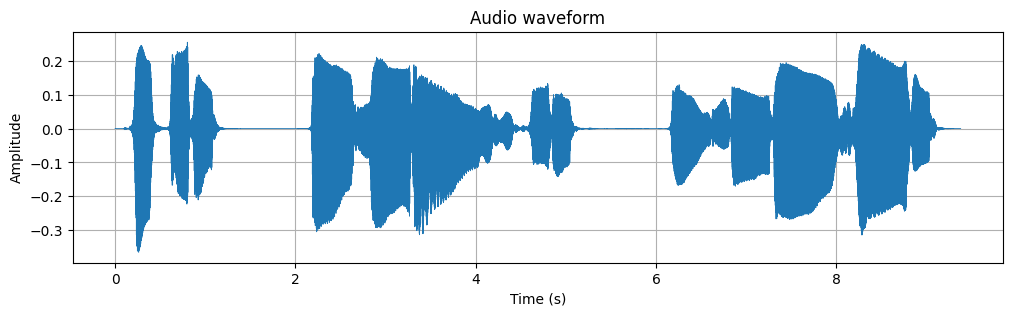

In [2]:
AUDIO_PATH = None  # Set to a filename to analyze a different recording.
MAX_SECONDS = 18

if AUDIO_PATH is None:
    candidates = [Path('sounds/sax-phrase.wav'), Path('../sounds/sax-phrase.wav')]
else:
    candidates = [Path(AUDIO_PATH).expanduser()]

candidates = [candidate.resolve() for candidate in candidates]
path = next((candidate for candidate in candidates if candidate.is_file()), None)
if path is None:
    checked = ', '.join(str(candidate) for candidate in candidates)
    raise FileNotFoundError(f'Audio file not found. Checked: {checked}')
audio = es.MonoLoader(filename=str(path), sampleRate=SR)()
audio = np.asarray(audio[:int(MAX_SECONDS * SR)], dtype=np.float32)

if len(audio) < 2 * FRAME_SIZE:
    raise ValueError('The recording must be longer than two analysis frames.')

duration = len(audio) / SR
t_audio = np.arange(len(audio)) / SR
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_audio[::10], audio[::10], lw=0.6)
ax.set(xlabel='Time (s)', ylabel='Amplitude', title='Audio waveform')
plt.show()
display(Audio(audio, rate=SR))

## 2. From consecutive frames to spectral changes

### 2.1 Short-time spectral representation

We compute the magnitude spectrum for each windowed frame, as in the first notebook. At time index $m$, the spectrum is $S_m[k] = |X_m[k]|$. A spectrogram displays these spectra as a function of time.

A **single-frame** descriptor depends on one $S_m[k]$. A **multiple-frame** descriptor can also depend on $S_{m-1}[k]$, $S_{m+1}[k]$, or on an entire feature sequence.

### 2.2 Spectral flux

**Spectral flux** measures the change between the magnitude spectra of adjacent frames. One common form uses only *increases* in magnitude:

$$
F[m] = \sum_k \max\bigl(0, S_m[k] - S_{m-1}[k]\bigr).
$$

A sudden new note or an impact creates changes across frequency bins and typically produces a peak in flux. The exact value depends on the norm, spectral scaling, normalization and rectification employed. We illustrate the half-rectified L1 form with Essentia's `Flux` algorithm.

High spectral flux means **a change has occurred**, but it does not guarantee that a perceptual musical note has begun: noise bursts, vibrato, dynamics or articulation may also produce changes.

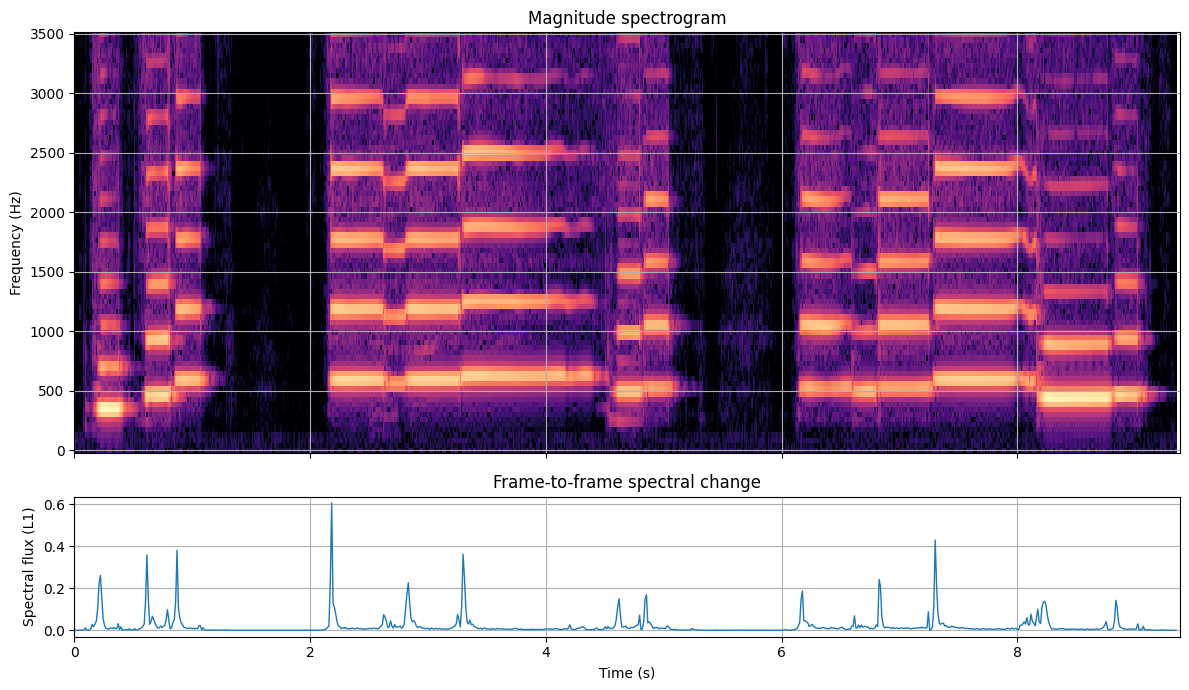

In [3]:
window = es.Windowing(type='hann')
fft = es.FFT()

frames = list(es.FrameGenerator(audio, frameSize=FRAME_SIZE, hopSize=HOP_SIZE,
                                startFromZero=True, validFrameThresholdRatio=1))
complex_spectra = np.asarray([fft(window(frame)) for frame in frames])
magnitudes = np.abs(complex_spectra).astype(np.float32)
phases = np.angle(complex_spectra).astype(np.float32)
frame_times = np.arange(len(frames)) * (HOP_SIZE / SR)

flux_algorithm = es.Flux(halfRectify=True, norm='L1')
flux = np.asarray([flux_algorithm(spec) for spec in magnitudes], dtype=float)

spectra_db = 20 * np.log10(np.maximum(magnitudes.T, EPS))
freqs = np.fft.rfftfreq(FRAME_SIZE, d=1/SR)
view_bins = freqs <= 3500

fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                        gridspec_kw={'height_ratios': [3, 1]})
axs[0].pcolormesh(frame_times, freqs[view_bins], spectra_db[view_bins],
                  shading='auto', cmap='magma', vmin=spectra_db.max()-90, vmax=spectra_db.max())
axs[0].set(ylabel='Frequency (Hz)', title='Magnitude spectrogram')
axs[1].plot(frame_times, flux, color='tab:blue', lw=1)
axs[1].set(xlabel='Time (s)', ylabel='Spectral flux (L1)', title='Frame-to-frame spectral change')
axs[-1].set_xlim(0, duration)
plt.tight_layout()
plt.show()

## 3. From spectral changes to detected onsets

### 3.1 Onset detection functions (ODFs)

An **onset detection function** assigns a value to each frame that indicates the likelihood or strength of an attack. We compare three related methods available through Essentia's `OnsetDetection`:

- **Spectral flux (`flux`)**: looks at changes in spectral magnitudes.
- **High-frequency content (`hfc`)**: emphasizes high-frequency energy, which often rises sharply during percussive attacks. A commonly used version is $\mathrm{HFC}[m] = \sum_k k\, |X_m[k]|^2$; the frequency-bin weight $k$ makes bright attacks stand out (Essentia also implements other HFC variants).
- **Complex domain (`complex`)**: accounts for changes in both spectral magnitude and phase; it can be helpful for pitched onsets as well as transients.

`OnsetDetection` **maintains state across consecutive calls**. We therefore instantiate each method once and feed frames **in temporal order**. The `Onsets` algorithm then combines, normalizes, smooths and peak-picks one or several ODF trajectories to return **times in seconds**.

The main distinction is:

**Spectral feature → onset detection function → onset-time decisions**.

The onset-time estimator may miss quiet attacks or insert extra detections. Its output is an estimate, not a transcription of the score.

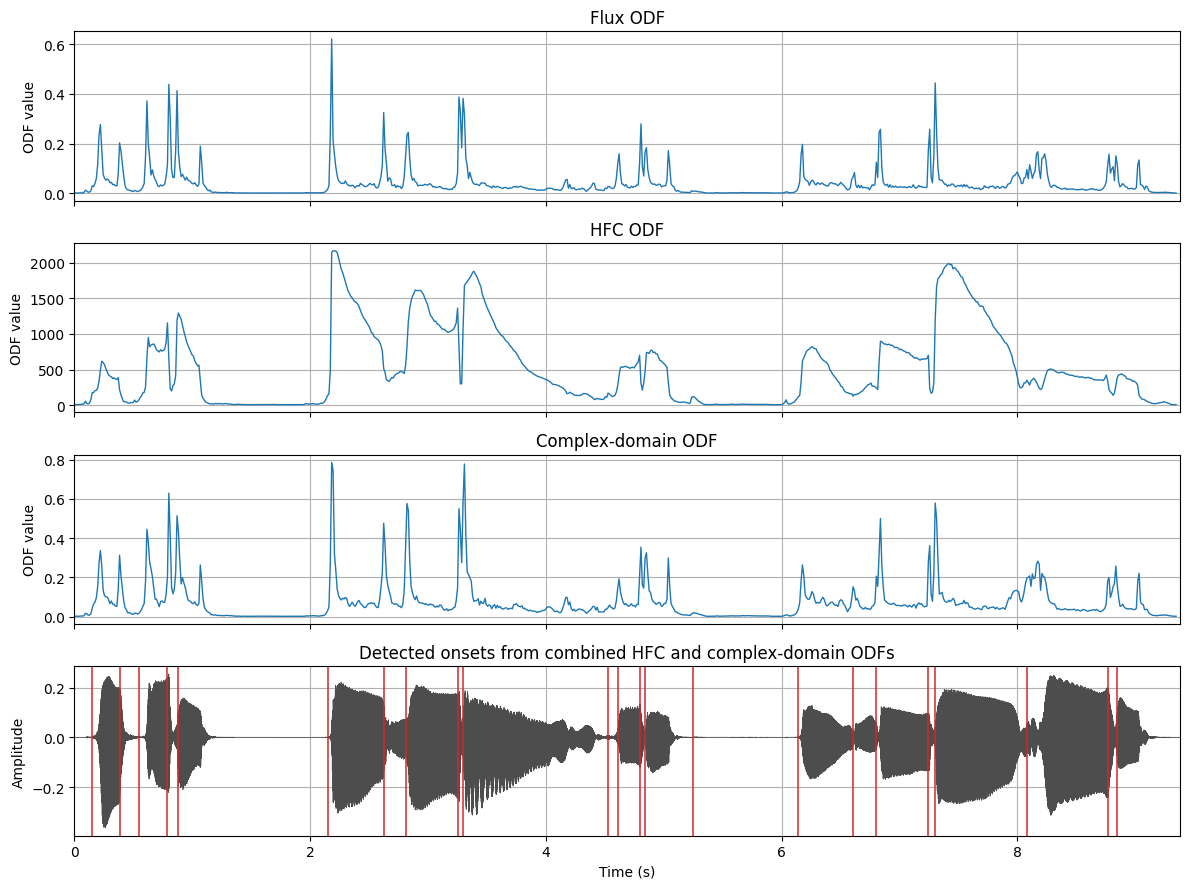

Flux onsets (s):     [0.16 0.38 0.58 0.78 1.07 2.17 2.44 2.6  2.8  3.23 4.01 4.16 4.39 4.53
 4.6  4.78 5.04 6.15 6.61 6.78 7.24 7.72 7.92 8.1  8.16 8.64 8.74 9.02]
HFC onsets (s):      [0.15 0.52 0.88 2.14 2.82 3.32 4.52 4.61 4.86 5.24 6.13 6.68 6.83 7.31
 8.24 8.86]
Combined onsets (s): [0.15 0.38 0.55 0.79 0.88 2.15 2.62 2.81 3.25 3.3  4.53 4.61 4.79 4.84
 5.25 6.14 6.61 6.8  7.24 7.3  8.08 8.77 8.85]


In [4]:
# Use the same FFT magnitude/phase sequence for all the detection functions.
od_flux = es.OnsetDetection(method='flux', sampleRate=SR)
od_hfc = es.OnsetDetection(method='hfc', sampleRate=SR)
od_complex = es.OnsetDetection(method='complex', sampleRate=SR)

odf_flux, odf_hfc, odf_complex = [], [], []
for mag, phase in zip(magnitudes, phases):
    odf_flux.append(float(od_flux(mag, phase)))
    odf_hfc.append(float(od_hfc(mag, phase)))
    odf_complex.append(float(od_complex(mag, phase)))
odf_flux = np.asarray(odf_flux)
odf_hfc = np.asarray(odf_hfc)
odf_complex = np.asarray(odf_complex)

# Onsets expects rows = detection functions and columns = time frames.
def find_onsets(*odfs, weights=None):
    weights = list(weights) if weights is not None else [1.0] * len(odfs)
    detections = essentia.array(odfs)
    return np.asarray(
        es.Onsets(frameRate=SR/HOP_SIZE)(detections, weights), dtype=float
    )

onsets_flux = find_onsets(odf_flux)
onsets_hfc = find_onsets(odf_hfc)
onsets_combined = find_onsets(odf_hfc, odf_complex, weights=[1, 1])

fig, axs = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, values, title in zip(axs[:3], [odf_flux, odf_hfc, odf_complex],
                              ['Flux ODF', 'HFC ODF', 'Complex-domain ODF']):
    ax.plot(frame_times, values, lw=1)
    ax.set(ylabel='ODF value', title=title)
axs[3].plot(t_audio[::10], audio[::10], lw=.5, color='0.3', label='Audio')
for t in onsets_combined:
    axs[3].axvline(t, color='tab:red', lw=1.1)
axs[3].set(title='Detected onsets from combined HFC and complex-domain ODFs',
           xlabel='Time (s)', ylabel='Amplitude', xlim=(0, duration))
plt.tight_layout()
plt.show()
print('Flux onsets (s):    ', np.round(onsets_flux, 2))
print('HFC onsets (s):     ', np.round(onsets_hfc, 2))
print('Combined onsets (s):', np.round(onsets_combined, 2))

### 3.2 Event segmentation from onset times

An onset detector gives **candidate event starts**. A simple, illustrative segmentation uses the onset times as **boundaries** between adjacent intervals. This is useful for computing descriptors per event region, but the boundaries are not necessarily the real note offsets. Resonances, overlapping notes and reverberation may continue across them.

The next visualization places onset boundaries over the waveform and allows us to **hear estimated intervals**. Listen to the intervals and check whether the detected boundaries align with audible attacks. For recordings with sustained notes or concurrent sources, onset-based segmentation is only one possible representation.

A different task, **homogeneity-based audio segmentation**, searches for changes in the statistics of feature sequences (e.g., Essentia `SBic`). Such boundaries need not coincide with note onsets; it is not used here because the lecture's illustrated example is onset-based segmentation.

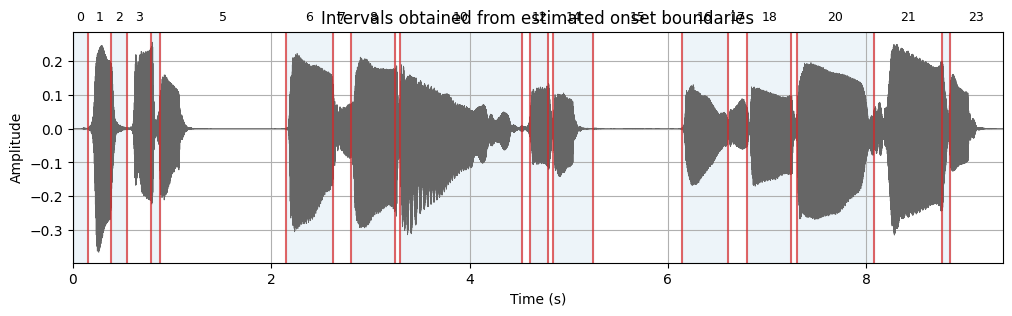

23 interior onsets define 24 consecutive intervals.
First intervals (start, stop, duration in seconds):
   0:  0.00 –  0.15   (0.15)
   1:  0.15 –  0.38   (0.23)
   2:  0.38 –  0.55   (0.16)
   3:  0.55 –  0.79   (0.24)
   4:  0.79 –  0.88   (0.09)
   5:  0.88 –  2.15   (1.27)
   6:  2.15 –  2.62   (0.48)
   7:  2.62 –  2.81   (0.19)
   8:  2.81 –  3.25   (0.44)
   9:  3.25 –  3.30   (0.05)


In [5]:
# Keep 0 and the end of the recording as interval boundaries.
internal_onsets = np.asarray(onsets_combined, dtype=float)
internal_onsets = internal_onsets[(internal_onsets > 0.10) &
                                  (internal_onsets < duration - 0.10)]
segment_boundaries = np.unique(np.r_[0.0, internal_onsets, duration])
segments = list(zip(segment_boundaries[:-1], segment_boundaries[1:]))

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_audio[::10], audio[::10], lw=.6, color='0.4')
for i, (start, stop) in enumerate(segments):
    if i % 2 == 0:
        ax.axvspan(start, stop, color='tab:blue', alpha=.08)
    if stop - start > .10:
        ax.text((start + stop) / 2, .90 * float(np.max(np.abs(audio))),
                str(i), ha='center', va='center', fontsize=9)
for boundary in internal_onsets:
    ax.axvline(boundary, color='tab:red', alpha=.7)
ax.set(xlabel='Time (s)', ylabel='Amplitude', title='Intervals obtained from estimated onset boundaries', xlim=(0, duration))
plt.show()
print(f'{len(internal_onsets)} interior onsets define {len(segments)} consecutive intervals.')
print('First intervals (start, stop, duration in seconds):')
for i, (start, stop) in enumerate(segments[:10]):
    print(f'  {i:2d}: {start:5.2f} – {stop:5.2f}   ({stop-start:4.2f})')

### 3.3 Listening to detected onsets

A plot can suggest that an onset aligns with a transient, but **listening** remains useful. The code below overlays a brief click at every estimated onset and plays the result. The click is for demonstration; it is **not** part of the source recording.

In [6]:
click_audio = np.asarray(audio, dtype=np.float64).copy()
click_len = int(.012 * SR)
click_t = np.arange(click_len) / SR
click = 0.16 * np.sin(2 * np.pi * 1800 * click_t) * np.exp(-click_t / .002)
for onset in onsets_combined:
    start = int(round(float(onset) * SR))
    if 0 <= start < len(click_audio):
        n = min(len(click), len(click_audio)-start)
        click_audio[start:start+n] += click[:n]
display(Audio(click_audio.astype(np.float32), rate=SR))

### Inter-onset intervals

An inter-onset interval (IOI) is the elapsed time between two consecutive detected attacks. Use the click-track playback above to listen for short and long gaps. A missed detection joins two adjacent intervals into one longer interval. A spurious detection splits one interval into two.

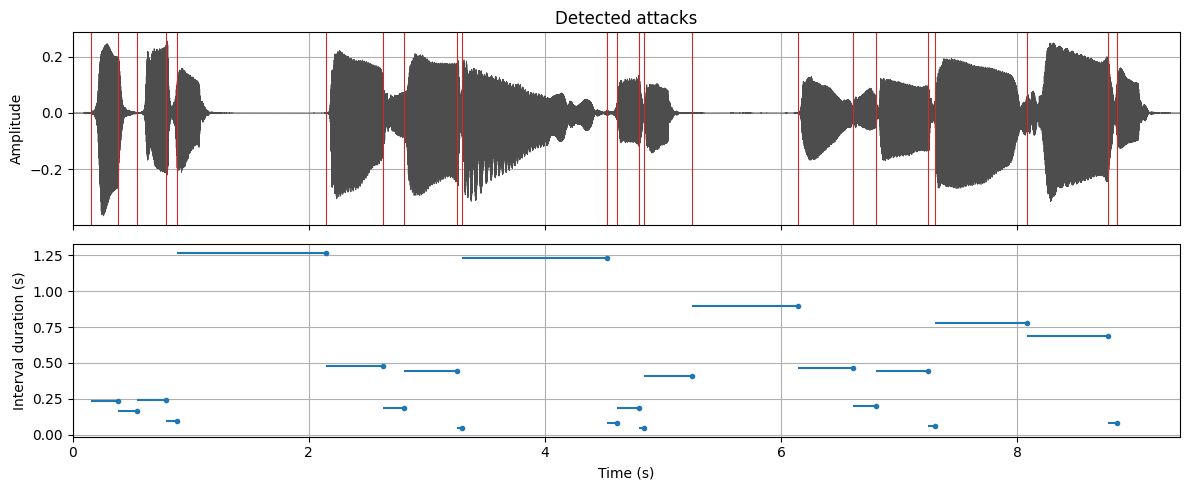

In [7]:
onset_times = np.unique(onsets_combined)
iois = np.diff(onset_times)
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t_audio[::10], audio[::10], lw=.6, color='0.3')
for onset in onset_times:
    axes[0].axvline(onset, color='tab:red', lw=.8)
axes[0].set(ylabel='Amplitude', title='Detected attacks')
if iois.size:
    axes[1].hlines(iois, onset_times[:-1], onset_times[1:], color='tab:blue')
    axes[1].plot(onset_times[1:], iois, '.', color='tab:blue')
    if iois.size <= 16:
        for start, stop, interval in zip(onset_times[:-1], onset_times[1:], iois):
            axes[1].annotate(f'{interval:.2f}', ((start + stop) / 2, interval),
                             xytext=(0, 4), textcoords='offset points', ha='center')
else:
    axes[1].text(.5, .5, 'At least two detected onsets are needed.',
                 transform=axes[1].transAxes, ha='center')
axes[1].set(xlabel='Time (s)', ylabel='Interval duration (s)', xlim=(0, duration))
plt.tight_layout()
plt.show()

## 4. Predominant pitch across several frames

A short-time spectrum may support several plausible fundamental frequencies. In polyphonic audio, the problem is harder: the spectrum contains harmonics from **multiple sources**. Frame-by-frame pitch salience alone does not decide which candidates form the dominant melodic line.

The slide summarizes the *MELODIA* approach as:

**Spectral peaks → pitch salience → pitch contour creation → melody selection → predominant $f_0$ sequence.**

A **pitch contour** follows compatible pitch candidates across time. Tracking favors continuity and makes use of evidence from neighboring frames. The predominant pitch is the contour selected as the likely dominant melody, **not the fundamental frequency of every simultaneous note**.

Essentia's `PredominantPitchMelodia` implements the complete pipeline and returns:

- `pitch`: one estimated predominant frequency in hertz per frame; zero denotes *unvoiced / no predominant pitch detected*.
- `pitchConfidence`: a confidence measure for each estimate.

The algorithm uses shorter hops than our onset analysis. It is recommended to pass the input through `EqualLoudness` first. `guessUnvoiced=False` avoids forcing pitch estimates in regions where no salient melody is detected.

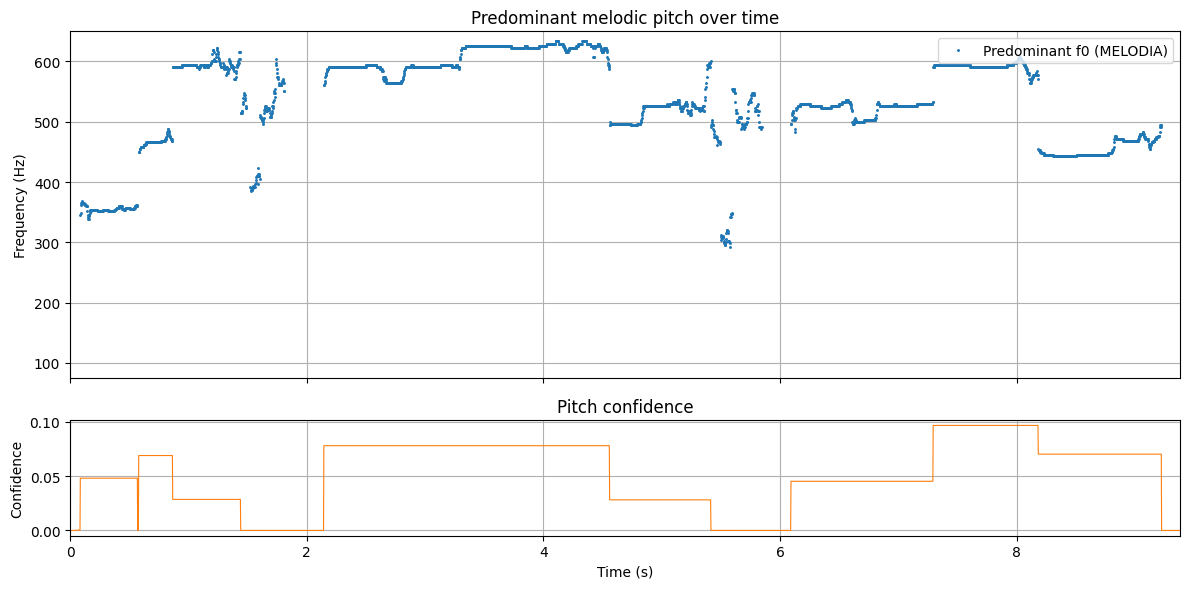

Frames with a detected predominant pitch: 93.7%


In [8]:
melodia = es.PredominantPitchMelodia(
    sampleRate=SR,
    frameSize=PITCH_FRAME_SIZE,
    hopSize=PITCH_HOP_SIZE,
    minFrequency=80,
    maxFrequency=1600,
    guessUnvoiced=False,
)
equalized_audio = es.EqualLoudness()(audio)
predominant_pitch, pitch_confidence = melodia(equalized_audio)
predominant_pitch = np.asarray(predominant_pitch, dtype=float)
pitch_confidence = np.asarray(pitch_confidence, dtype=float)
# Documentation: pitch[0] is associated with the start of the recording (t = 0).
pitch_times = np.arange(len(predominant_pitch)) * PITCH_HOP_SIZE / SR
voiced = predominant_pitch > 0
pitch_for_plot = np.where(voiced, predominant_pitch, np.nan)

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                        gridspec_kw={'height_ratios':[3,1]})
axs[0].plot(pitch_times, pitch_for_plot, '.', ms=2.2, label='Predominant f0 (MELODIA)')
axs[0].set(ylabel='Frequency (Hz)', title='Predominant melodic pitch over time', ylim=(75, 650))
axs[0].legend(loc='upper right')
axs[1].plot(pitch_times, pitch_confidence, lw=.8, color='tab:orange')
axs[1].set(xlabel='Time (s)', ylabel='Confidence', title='Pitch confidence', xlim=(0, duration))
plt.tight_layout()
plt.show()
print(f'Frames with a detected predominant pitch: {np.mean(voiced):.1%}')

### 4.1 Representing the melody as notes

Pitch frequencies can also be expressed using the MIDI semitone scale:

$$
 p = 69 + 12 \log_2\left(\frac{f_0}{440}\right), \qquad f_0 > 0.
$$

Here $p=69$ corresponds to A4 = 440 Hz. Mapping the frequency trajectory to this scale makes **pitch steps** visually clear. The following display is not a quantized musical transcription; it is the continuous output of predominant pitch estimation expressed in semitones.

In polyphonic or noisy passages, a pitch tracker can show **octave errors**, missing pitches, or a switch to an accompaniment voice. This is why the time continuity and contour selection stages matter.

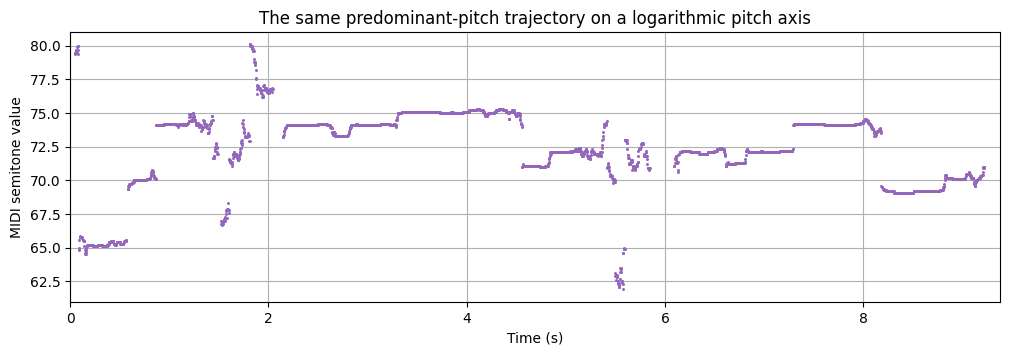

In [9]:
with np.errstate(divide='ignore', invalid='ignore'):
    midi_pitch = np.where(voiced, 69 + 12 * np.log2(np.maximum(predominant_pitch, EPS) / 440), np.nan)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(pitch_times, midi_pitch, '.', ms=2.3, color='tab:purple')
ax.set(xlabel='Time (s)', ylabel='MIDI semitone value',
       title='The same predominant-pitch trajectory on a logarithmic pitch axis', xlim=(0, duration))
plt.show()

### 4.2 Listening to the predominant-pitch contour: sinusoidal resynthesis

A pitch tracker produces a sequence of estimated fundamental frequencies, one per analysis frame. We can **hear the melodic contour** by synthesizing a sinusoid whose instantaneous frequency follows those estimates:

$$
y[n] = a[n]\sin\!\bigl(\phi[n]\bigr), \qquad
\phi[n] = \phi[n-1] + \frac{2\pi f_0[n]}{f_s}.
$$

Here $f_0[n]$ is the estimated pitch converted from the frame rate to the audio sample rate, $f_s$ is the audio sampling rate, $\phi[n]$ is the accumulated phase, and $a[n]$ is a simple amplitude envelope.

The code below:

1. **Interpolates between adjacent pitch estimates** within each continuous *voiced* region, avoiding abrupt frequency steps between analysis frames.
2. **Produces silence in unvoiced regions** (where MELODIA returns a non-positive pitch). A short fade-in/fade-out around each voiced region prevents clicks.
3. **Accumulates phase** rather than resetting it each frame, to obtain a continuous sinusoid.

Compare the original audio with the sinusoidal version. The sinusoid preserves the detected **pitch movement and approximate voiced/unvoiced timing**, but not the original **timbre, loudness dynamics, or accompaniment**. Any audible wrong notes or octave jumps reflect the pitch estimates, not the synthesis itself.

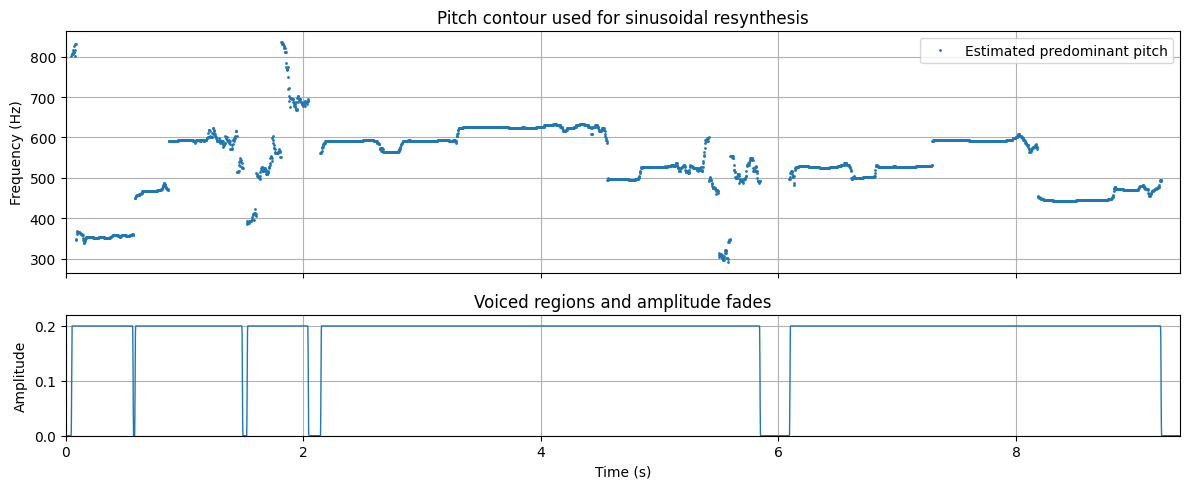

Voiced regions: 5
Original recording:


Sinusoidal resynthesis of the estimated pitch contour:


In [10]:
# Synthesize a pure sinusoid following the pitch estimates from Section 4.
# Use the existing predominant_pitch, pitch_times, audio, SR and PITCH_HOP_SIZE.

n_samples = len(audio)
f0_at_sample_rate = np.zeros(n_samples, dtype=np.float64)
amplitude = np.zeros(n_samples, dtype=np.float64)

valid_pitch = np.isfinite(predominant_pitch) & (predominant_pitch > 0)
# Find the [start, stop) frame indices for each consecutive voiced region.
voiced_edges = np.flatnonzero(np.diff(np.r_[False, valid_pitch, False]))
voiced_regions = voiced_edges.reshape(-1, 2)

FADE_MS = 8       # Short attack/release to avoid clicks at voiced boundaries.
SINE_AMPLITUDE = 0.20
fade_samples = max(1, int(round(FADE_MS * SR / 1000)))

for first_frame, stop_frame in voiced_regions:
    first_sample = min(first_frame * PITCH_HOP_SIZE, n_samples)
    stop_sample = min(stop_frame * PITCH_HOP_SIZE, n_samples)
    if stop_sample <= first_sample:
        continue

    sample_indices = np.arange(first_sample, stop_sample)
    # np.interp handles even a voiced region containing just one pitch frame.
    f0_at_sample_rate[first_sample:stop_sample] = np.interp(
        sample_indices / SR,
        pitch_times[first_frame:stop_frame],
        predominant_pitch[first_frame:stop_frame]
    )

    # Constant amplitude inside each voiced region, with smooth boundary fades.
    amplitude[first_sample:stop_sample] = SINE_AMPLITUDE
    fade_length = min(fade_samples, (stop_sample - first_sample) // 2)
    if fade_length > 0:
        fade_in = np.sin(np.linspace(0, np.pi / 2, fade_length)) ** 2
        amplitude[first_sample:first_sample + fade_length] *= fade_in
        amplitude[stop_sample - fade_length:stop_sample] *= fade_in[::-1]

# Integrating instantaneous frequency gives a continuous phase in radians.
phase = 2 * np.pi * np.cumsum(f0_at_sample_rate) / SR
synthesized_pitch = amplitude * np.sin(phase)

fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True,
                        gridspec_kw={'height_ratios': [2, 1]})
axs[0].plot(pitch_times, np.where(valid_pitch, predominant_pitch, np.nan),
            '.', markersize=2, label='Estimated predominant pitch')
axs[0].set(ylabel='Frequency (Hz)', title='Pitch contour used for sinusoidal resynthesis')
axs[0].legend(loc='upper right')
axs[1].plot(np.arange(n_samples)[::100] / SR, amplitude[::100], linewidth=1)
axs[1].set(xlabel='Time (s)', ylabel='Amplitude', title='Voiced regions and amplitude fades',
           xlim=(0, duration), ylim=(0, SINE_AMPLITUDE * 1.1))
plt.tight_layout()
plt.show()

print(f'Voiced regions: {len(voiced_regions)}')
print('Original recording:')
display(Audio(audio, rate=SR, normalize=False))
print('Sinusoidal resynthesis of the estimated pitch contour:')
display(Audio(synthesized_pitch, rate=SR, normalize=False))


## 5. Statistics of single-frame features

The same recording can contain thousands of frame-wise values of **RMS**, **spectral centroid** or **MFCC coefficients**. To represent the complete sound (or a selected segment) using a **fixed-size descriptor vector**, we aggregate the sequence over time.

For values $z[0], \ldots, z[M-1]$ of one feature:

**Arithmetic mean (first moment):**

$$
\mu = \frac{1}{M} \sum_{m=0}^{M-1} z[m].
$$

**Variance (second central moment):**

$$
\sigma^2 = \frac{1}{M}\sum_{m=0}^{M-1} \bigl(z[m]-\mu\bigr)^2.
$$

**Skewness (normalized third central moment):**

$$
\gamma_1 = \frac{1}{M\,\sigma^3}
\sum_{m=0}^{M-1} \bigl(z[m]-\mu\bigr)^3,\qquad \sigma>0.
$$

- **Mean** describes the average level of a feature.
- **Variance** measures its temporal dispersion around the mean.
- **Skewness** measures asymmetry: high positive skew often reflects a distribution with occasional unusually large values.

We use population statistics (division by $M$), appropriate for summarizing the observed set of frames. For zero variance, skewness is undefined; the helper below returns 0 for numerical convenience and labels that convention explicitly. These statistics **discard frame order**, even though the original temporal sequences were used to compute them.

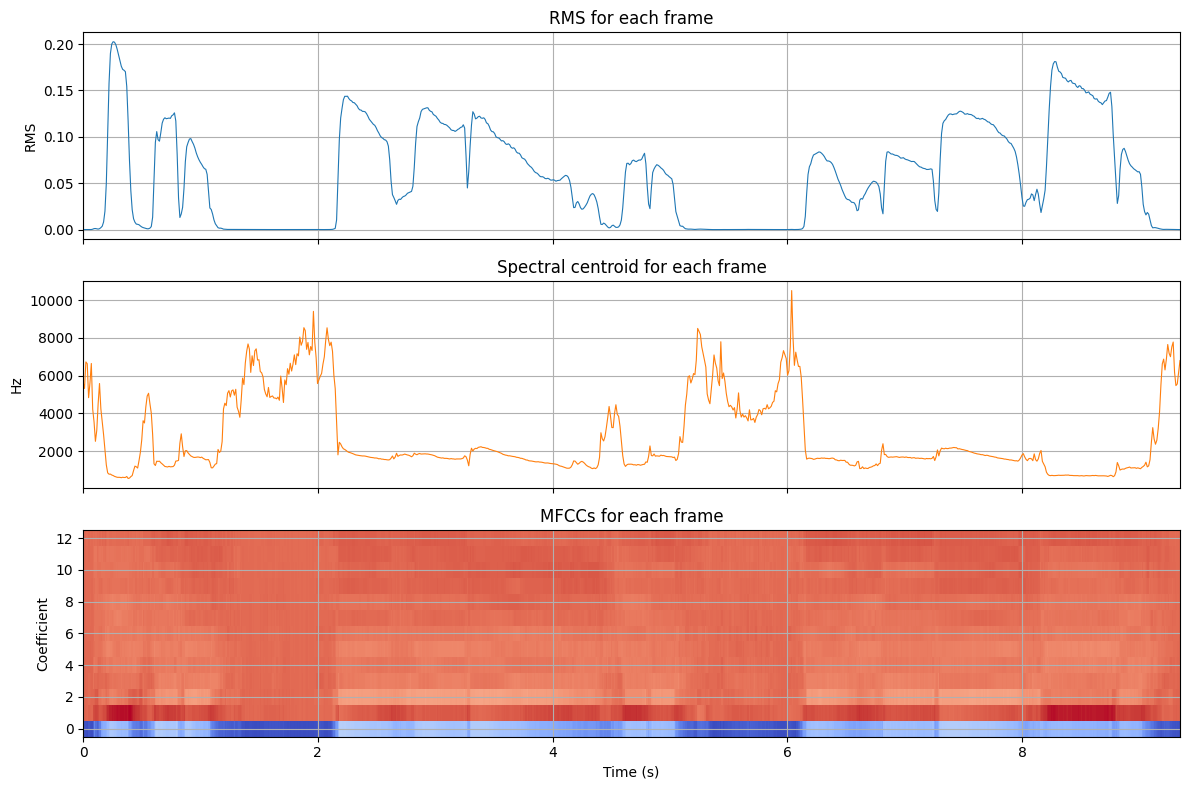

RMS: (806,) Centroid: (806,) MFCC: (806, 13)


In [11]:
# Frame-based descriptors, as in the preceding single-frame example.
rms_alg = es.RMS()
centroid_alg = es.Centroid(range=SR / 2)
mfcc_alg = es.MFCC(inputSize=magnitudes.shape[1], sampleRate=SR,
                   numberBands=40, numberCoefficients=13,
                   highFrequencyBound=11000, type='power', logType='dbpow')

rms = np.asarray([rms_alg(frame) for frame in frames], dtype=float)
centroid = np.asarray([centroid_alg(spec) if np.max(spec) > EPS else 0.0
                       for spec in magnitudes], dtype=float)
mfcc = np.asarray([mfcc_alg(spec)[1] for spec in magnitudes], dtype=float)

fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axs[0].plot(frame_times, rms, lw=.8)
axs[0].set(ylabel='RMS', title='RMS for each frame')
axs[1].plot(frame_times, centroid, lw=.8, color='tab:orange')
axs[1].set(ylabel='Hz', title='Spectral centroid for each frame')
axs[2].imshow(mfcc.T, origin='lower', aspect='auto', interpolation='nearest',
              extent=[frame_times[0], frame_times[-1], -0.5, mfcc.shape[1]-.5], cmap='coolwarm')
axs[2].set(xlabel='Time (s)', ylabel='Coefficient', title='MFCCs for each frame')
plt.tight_layout()
plt.show()
print('RMS:', rms.shape, 'Centroid:', centroid.shape, 'MFCC:', mfcc.shape)

### MFCC deltas

An MFCC delta estimates how quickly a coefficient changes. Here we fit a slope over five frames using a symmetric regression window. The slope is in coefficient units per second. The first and last two frames have no full window. Compare sustained regions and attacks in the waveform, coefficient, and delta plots. A large coefficient value can stay nearly constant, giving a small delta.

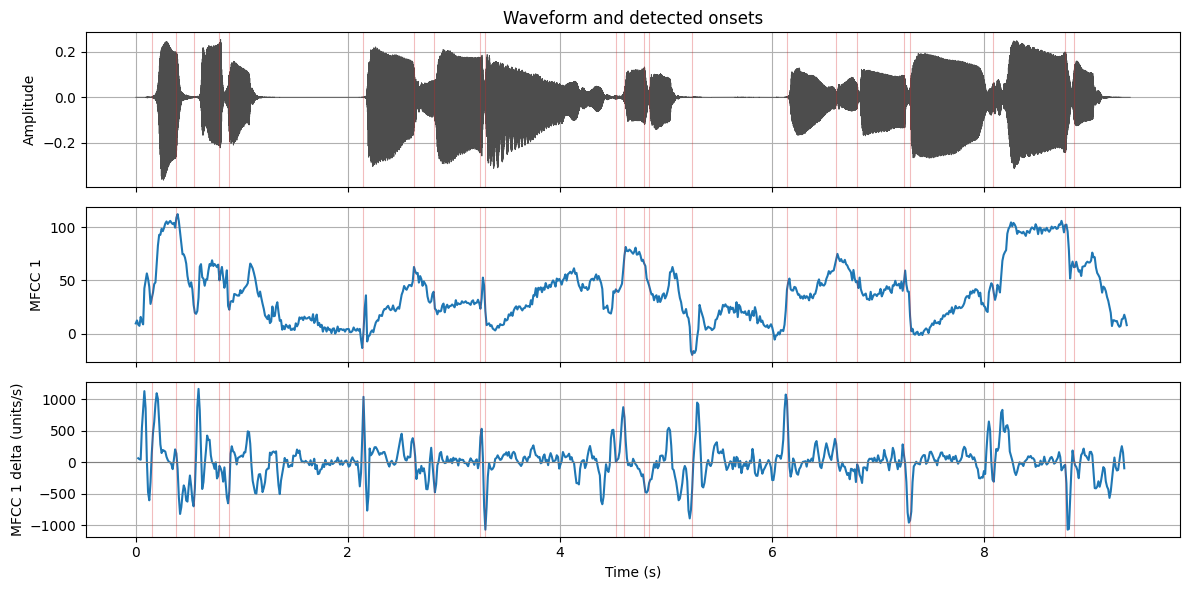

In [12]:
coefficient = 1
mfcc_track = mfcc[:, coefficient]
offsets = np.arange(-2, 3) * (HOP_SIZE / SR)
delta = np.full(len(mfcc_track), np.nan)
if len(mfcc_track) >= len(offsets):
    windows = np.lib.stride_tricks.sliding_window_view(mfcc_track, len(offsets))
    delta[2:-2] = windows @ offsets / (offsets @ offsets)

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t_audio[::10], audio[::10], lw=.6, color='0.3')
axes[1].plot(frame_times, mfcc_track)
axes[2].plot(frame_times, delta)
axes[2].axhline(0, color='0.5', lw=.8)
for ax in axes:
    for onset in onsets_combined:
        ax.axvline(onset, color='tab:red', alpha=.3, lw=.8)
axes[0].set(ylabel='Amplitude', title='Waveform and detected onsets')
axes[1].set(ylabel=f'MFCC {coefficient}')
axes[2].set(xlabel='Time (s)', ylabel=f'MFCC {coefficient} delta (units/s)')
plt.tight_layout()
plt.show()

### 5.1 Summarize a complete recording: NumPy and Essentia

First we compute the three moments explicitly to connect the formulas with the code. Then we use Essentia's **`PoolAggregator`**, which can calculate these statistics for scalar sequences and each dimension of vector features such as MFCCs. Unlike a list of raw frames, the resulting aggregate has a **fixed dimensionality**.

Note that **RMS** and **spectral centroid** summarize different aspects of the recording, and their skewness values should not be compared as if they represented the same physical quantity.

In [13]:
def moments(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.array([np.nan, np.nan, np.nan])
    mean = values.mean()
    var = np.mean((values - mean)**2)
    skew = np.mean((values-mean)**3) / (var**1.5) if var > EPS else 0.0
    return np.array([mean, var, skew])

for name, data in [('RMS', rms), ('Spectral centroid (Hz)', centroid)]:
    mean, var, skew = moments(data)
    print(f'{name:23s}  mean={mean:10.4f}  variance={var:12.4f}  skewness={skew:7.3f}')

pool = essentia.Pool()
for r, c, coeffs in zip(rms, centroid, mfcc):
    pool.add('lowlevel.rms', float(r))
    pool.add('lowlevel.centroid', float(c))
    pool.add('lowlevel.mfcc', essentia.array(coeffs))

aggregated = es.PoolAggregator(defaultStats=['mean', 'var', 'skew'])(pool)
print()
print('Essentia PoolAggregator:')
print('Centroid mean:', float(aggregated['lowlevel.centroid.mean']))
print('Centroid variance:', float(aggregated['lowlevel.centroid.var']))
print('MFCC mean vector shape:', np.asarray(aggregated['lowlevel.mfcc.mean']).shape)
print('MFCC variance vector shape:', np.asarray(aggregated['lowlevel.mfcc.var']).shape)

RMS                      mean=    0.0592  variance=      0.0028  skewness=  0.446
Spectral centroid (Hz)   mean= 2659.6093  variance=4092378.9986  skewness=  1.341

Essentia PoolAggregator:
Centroid mean: 2659.611083984375
Centroid variance: 4092378.0
MFCC mean vector shape: (13,)
MFCC variance vector shape: (13,)


### 5.2 Interpret the distribution, not just its mean

Two recordings can have the same average centroid but very different temporal variation. For example, one can have a relatively constant brightness, while another has mostly a low centroid with a few very bright attacks.

A histogram makes the mean, variance and skewness more interpretable. It also shows why the amount of silence and the duration of the selected region affect global statistics. In some tasks it is useful to aggregate only **active frames**, but that choice must be explicit and consistent across recordings.

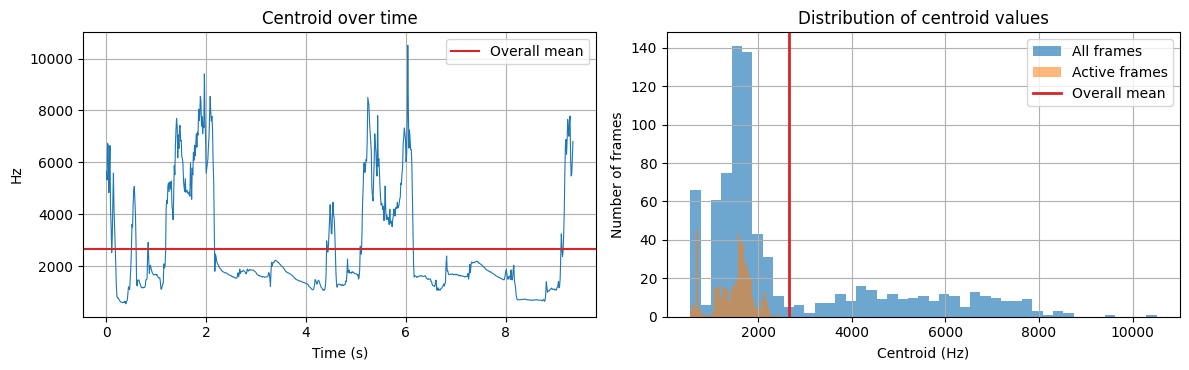

Active frames: 537/806 (66.6%)
                            Mean (Hz)       Variance (Hz²)    Skewness
All frames:                  2659.6          4092379.0         1.34
Active frames only:          1484.2           168790.7        -0.53


In [14]:
active = rms > 0.10 * np.max(rms)  # Illustrative activity threshold, not a silence classifier.
all_stats = moments(centroid)
active_stats = moments(centroid[active])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(frame_times, centroid, lw=.8)
axs[0].axhline(all_stats[0], color='tab:red', label='Overall mean')
axs[0].set(xlabel='Time (s)', ylabel='Hz', title='Centroid over time')
axs[0].legend()
axs[1].hist(centroid, bins=45, alpha=.65, label='All frames')
axs[1].hist(centroid[active], bins=45, alpha=.55, label='Active frames')
axs[1].axvline(all_stats[0], color='tab:red', lw=2, label='Overall mean')
axs[1].set(xlabel='Centroid (Hz)', ylabel='Number of frames', title='Distribution of centroid values')
axs[1].legend()
plt.tight_layout()
plt.show()
print(f'Active frames: {np.sum(active)}/{len(active)} ({np.mean(active):.1%})')
print('                            Mean (Hz)       Variance (Hz²)    Skewness')
print(f'All frames:            {all_stats[0]:12.1f} {all_stats[1]:18.1f} {all_stats[2]:12.2f}')
print(f'Active frames only:    {active_stats[0]:12.1f} {active_stats[1]:18.1f} {active_stats[2]:12.2f}')

### 5.3 Segment-level statistics: describe each interval separately

Instead of aggregating the **entire sound**, we can calculate a feature vector for each interval obtained in Section 3.2. This connects two ideas from the slides: segmentation and statistics of frame-based features.

For each interval we compute **centroid mean / variance / skewness**, **RMS mean**, and the mean values of the **13 MFCCs**. This is one possible descriptor representation of an event region. The resulting values still depend on the accuracy of the onset boundaries, and intervals may contain silence or parts of overlapping notes.

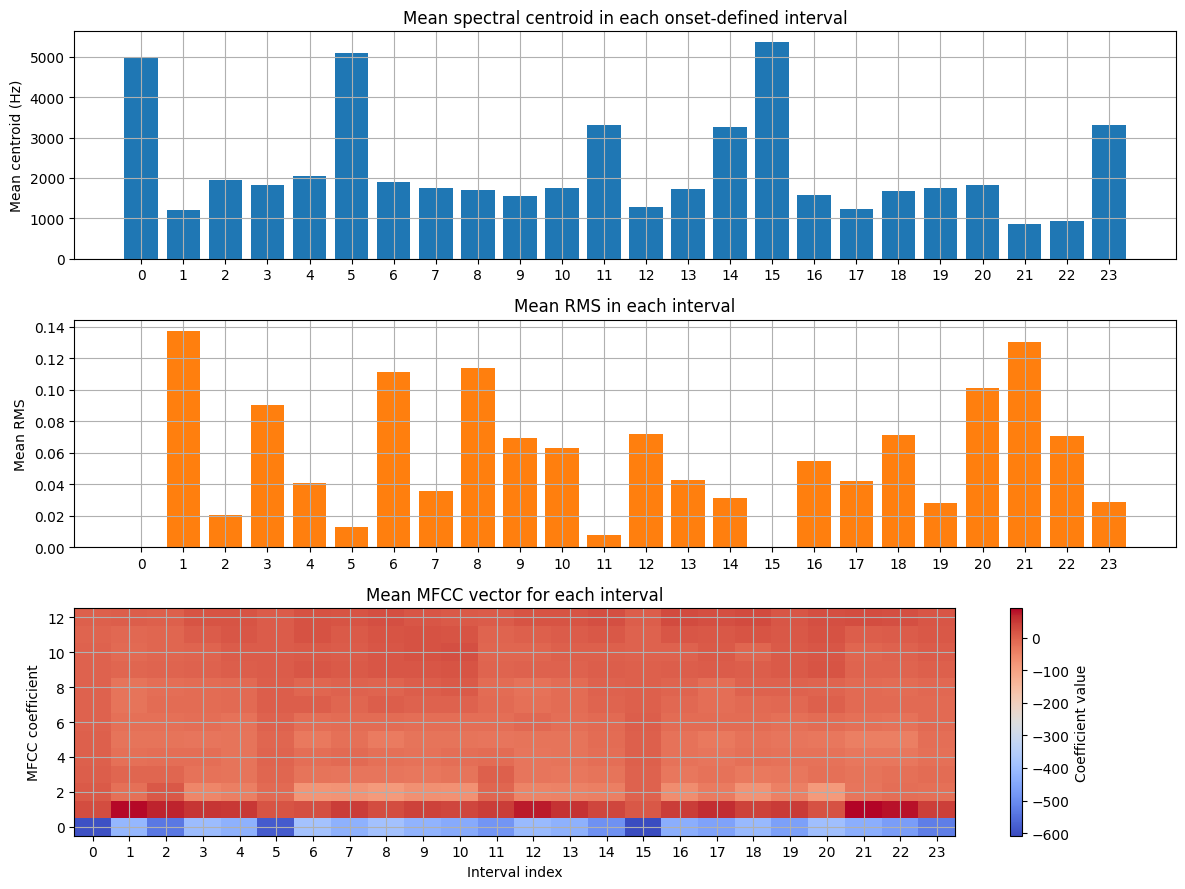

For each interval: 3 centroid statistics + 1 RMS statistic + 13 MFCC means = 17 numbers.


In [15]:
segment_descriptors = []
for i, (start, stop) in enumerate(segments):
    # One analysis frame per hop; select frames according to their start time.
    mask = (frame_times >= start) & (frame_times < stop)
    if not np.any(mask):
        continue
    cmean, cvar, cskew = moments(centroid[mask])
    segment_descriptors.append({
        'index': i, 'start': start, 'stop': stop,
        'centroid_mean': cmean, 'centroid_var': cvar, 'centroid_skew': cskew,
        'rms_mean': float(rms[mask].mean()),
        'mfcc_mean': mfcc[mask].mean(axis=0),
    })

labels = [str(d['index']) for d in segment_descriptors]
centroid_means = [d['centroid_mean'] for d in segment_descriptors]
rms_means = [d['rms_mean'] for d in segment_descriptors]
segment_mfcc_means = np.stack([d['mfcc_mean'] for d in segment_descriptors])

fig, axs = plt.subplots(3, 1, figsize=(12, 9))
axs[0].bar(labels, centroid_means)
axs[0].set(ylabel='Mean centroid (Hz)', title='Mean spectral centroid in each onset-defined interval')
axs[1].bar(labels, rms_means, color='tab:orange')
axs[1].set(ylabel='Mean RMS', title='Mean RMS in each interval')
im = axs[2].imshow(segment_mfcc_means.T, aspect='auto', origin='lower', cmap='coolwarm')
axs[2].set(xticks=np.arange(len(labels)), xticklabels=labels, xlabel='Interval index',
           ylabel='MFCC coefficient', title='Mean MFCC vector for each interval')
fig.colorbar(im, ax=axs[2], label='Coefficient value')
plt.tight_layout()
plt.show()
print('For each interval: 3 centroid statistics + 1 RMS statistic + 13 MFCC means = 17 numbers.')

## 6. A guided event inspector

This optional interactive view connects the **waveform**, **spectral centroid** and **predominant pitch** for one onset-defined interval. It also plays that interval. Choose any detected interval in the control and observe how different descriptors summarize different properties of the *same* audio region.

The control illustrates a concept rather than setting a task or asking for a submission. If `ipywidgets` is unavailable, the first interval is displayed instead.

In [16]:
def inspect_interval(index=0):
    interval = segment_descriptors[int(index)]
    start, stop = interval['start'], interval['stop']
    mask = (frame_times >= start) & (frame_times < stop)
    pmask = (pitch_times >= start) & (pitch_times < stop)
    a = audio[int(start * SR):int(stop * SR)]

    fig, axs = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
    local_time = np.arange(len(a))/SR + start
    axs[0].plot(local_time[::5], a[::5], lw=.65)
    axs[0].set(ylabel='Amplitude', title=f'Interval {index}: {start:.2f}–{stop:.2f} s')
    axs[1].plot(frame_times[mask], centroid[mask], lw=1.2)
    axs[1].axhline(interval['centroid_mean'], color='tab:red', ls='--', label='Interval mean')
    axs[1].set(ylabel='Centroid (Hz)')
    axs[1].legend()
    axs[2].plot(pitch_times[pmask], pitch_for_plot[pmask], '.', ms=4)
    axs[2].set(xlabel='Time (s)', ylabel='Predominant f0 (Hz)', xlim=(start, stop))
    plt.tight_layout()
    plt.show()
    print('Mean centroid:', round(interval['centroid_mean'], 1), 'Hz;  mean RMS:',
          round(interval['rms_mean'], 4))
    if len(a) > 0:
        display(Audio(a, rate=SR, normalize=False))

try:
    import ipywidgets as widgets
    initial_interval = min(1, len(segment_descriptors)-1)  # Skip an initial silence if present.
    display(widgets.interact(inspect_interval,
                             index=widgets.IntSlider(value=initial_interval, min=0,
                                                     max=len(segment_descriptors)-1,
                                                     step=1, description='Interval')))
except ImportError:
    inspect_interval(min(1, len(segment_descriptors)-1))

interactive(children=(IntSlider(value=1, description='Interval', max=23), Output()), _dom_classes=('widget-int…

<function __main__.inspect_interval(index=0)>

## 7. Summary: from frames to a representation of musical time

This notebook demonstrates three complementary uses of spectral information across time:

| Goal | Input | Time-dependent idea | Output |
|---|---|---|---|
| **Event segmentation / onsets** | Consecutive spectra and phases | Detect spectral changes, combine ODFs and locate peaks | Onset times; candidate event boundaries |
| **Predominant pitch** | Spectral peaks and pitch-salience candidates | Connect pitch candidates into contours and select melody | Predominant $f_0$ trajectory, confidence and sinusoidal pitch-contour playback |
| **Statistics of features** | RMS, centroid and MFCC trajectories | Aggregate across all frames or within a segment | Means, variances, skewness; fixed-size vectors |

**What is lost when we summarize?** Event lists preserve approximate attack times; pitch tracks preserve melodic motion; aggregate statistics describe distributions but discard the original ordering of frames. The right representation depends on what we want to describe.

### Source and Essentia references

- **Lecture slides:** *9T1 — Spectral-based audio features*, especially **slides 16–20**.
- [Essentia onset detection tutorial](https://essentia.upf.edu/tutorial_rhythm_onsetdetection.html)
- [OnsetDetection](https://essentia.upf.edu/reference/std_OnsetDetection.html), [Onsets](https://essentia.upf.edu/reference/std_Onsets.html), [Flux](https://essentia.upf.edu/reference/std_Flux.html)
- [PredominantPitchMelodia](https://essentia.upf.edu/reference/std_PredominantPitchMelodia.html), [MELODIA tutorial](https://essentia.upf.edu/tutorial_pitch_melody.html)
- [PoolAggregator](https://essentia.upf.edu/reference/std_PoolAggregator.html)
- [SBic](https://essentia.upf.edu/reference/std_SBic.html) — a different segmentation method based on homogeneous feature distributions (not implemented above)

This is a **worked example**, not a set of student exercises. All equations use Jupyter-compatible inline and display math formatting.